# 04 · The timeline ML model and the GAN experiment

**Forecasting Antibiotic Resistance with AI** · Final Year Project · Hamza Afzal (models), Muhammad Ali Mirza (data and evolution), Suleman Saleh (platform)

Two parts added in the final sprint, at the supervisor's request:

1. **Timeline ML model.** The `/timeline` page showed only a simulation (hand-set equations). This model is trained on **real resistance trends**: the yearly resistant share of each organism (genus) and antibiotic, from the BV-BRC laboratory results that have a collection year. It forecasts the next years, and the website shows it beside the simulation.
2. **GAN experiment.** CTGAN, a generative adversarial network for tabular data, creates extra training rows for **rare** antibiotics and organisms; we test whether they improve the model on real data.

Code: `experiments/timeline_ml/timeline_model.py`, `backend/ml_models/timeline_ml.py`, `experiments/gan/ctgan_augment.py`. Run time: about 2 minutes (the GAN is not refitted here: see section B; `python experiments/gan/ctgan_augment.py generate` does it).

In [1]:
import os, sys, json, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, 'experiments'))
sys.path.insert(0, os.path.join(ROOT, 'experiments', 'timeline_ml'))
sys.path.insert(0, os.path.join(ROOT, 'experiments', 'gan'))
import timeline_model as tl

def show(fn):
    print(inspect.getsource(fn))

# A. Timeline ML model

## A1. The data: yearly resistance series

From the 553,223 laboratory results with a collection year (2000 to 2022), each (genus, antibiotic, year) with at least 20 results gives one point: the share of those results that were resistant. Built by `timeline_model.py series` (`build_series()`), saved as `experiments/timeline_ml/series.csv`.

In [2]:
series = tl.load_series()
n_series = series.groupby(['genus', 'Antibiotic']).ngroups
lengths = series.groupby(['genus', 'Antibiotic']).size()
print(f"{len(series):,} year points in {n_series} series, from {series['n'].sum():,} lab results; "
      f"series with >= 5 years: {(lengths >= 5).sum()}, >= 10 years: {(lengths >= 10).sum()}")
series.head()

2,619 year points in 467 series, from 534,996 lab results; series with >= 5 years: 186, >= 10 years: 110


,genus,Antibiotic,drug_class,year,resistant_pct,n
0,Acinetobacter,amikacin,aminoglycoside,2003,38.095,105
1,Acinetobacter,amikacin,aminoglycoside,2004,54.978,231
2,Acinetobacter,amikacin,aminoglycoside,2005,45.679,162
3,Acinetobacter,amikacin,aminoglycoside,2006,46.032,126
4,Acinetobacter,amikacin,aminoglycoside,2007,62.874,167


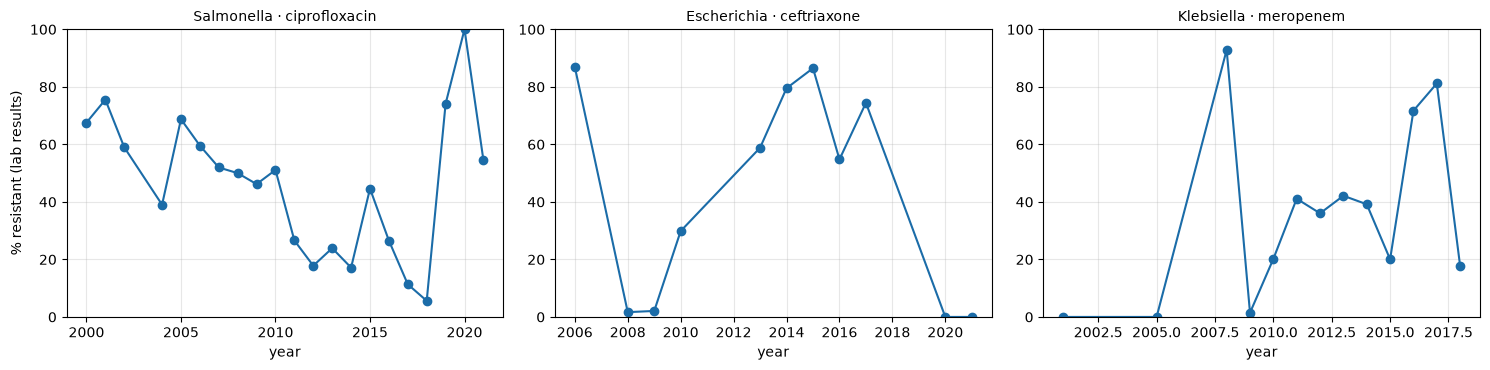

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (g, ab) in zip(axes, [('Salmonella', 'ciprofloxacin'), ('Escherichia', 'ceftriaxone'), ('Klebsiella', 'meropenem')]):
    s = series[(series.genus == g) & (series.Antibiotic == ab)]
    ax.plot(s.year, s.resistant_pct, 'o-', color='#1b6ca8')
    ax.set_title(f'{g} · {ab}', fontsize=10); ax.set_ylim(0, 100); ax.set_xlabel('year'); ax.grid(alpha=0.3)
axes[0].set_ylabel('% resistant (lab results)')
plt.tight_layout(); plt.show()

## A2. Features: only the years before the predicted year

To predict a year, the model sees only earlier years: the last three values, the gap since the last value, the recent slope, the historical mean, how much history there is, how many results the last value rests on, and the genus, antibiotic and drug class. It predicts the **change** from the last value.

In [4]:
show(tl.history_features)

def history_features(years, pcts, ns, t):
    """Features for predicting year t from the points strictly before t."""
    past = [(y, p, n) for y, p, n in zip(years, pcts, ns) if y < t]
    if len(past) < 1:
        return None
    py = np.array([p[0] for p in past], float)
    pp = np.array([p[1] for p in past], float)
    last3y, last3p = py[-3:], pp[-3:]
    slope = float(np.polyfit(last3y, last3p, 1)[0]) if len(last3y) >= 2 else 0.0
    lag = lambda k: float(pp[-k]) if len(pp) >= k else np.nan
    return {
        'lag1': lag(1), 'lag2': lag(2), 'lag3': lag(3),
        'gap1': float(t - py[-1]),
        'slope3': slope,
        'mean_past': float(pp.mean()),
        'n_past': float(len(pp)),
        'log_n1': float(np.log1p(past[-1][2])),
    }



## A3. Train on years up to 2016, test on 2017 to 2022

Every test year is in the model's future. Three baselines that need no learning: **last value** (next year = this year), **linear trend** (continue the recent slope), **historical mean**. Errors are mean absolute errors in percentage points (pp), with a 95% CI that resamples whole series.

In [5]:
model, metrics, test = tl.train_and_test(verbose=False)
rows = [{'method': k, 'MAE (pp)': round(v[0], 2), '95% CI': f'[{v[1][0]:.2f}, {v[1][1]:.2f}]'}
        for k, v in metrics['test_mae_pp'].items()]
display(pd.DataFrame(rows))
gains = pd.DataFrame([{'model better than': k, 'by (pp)': round(g['gain_pp'], 2),
                       '95% CI': f"[{g['ci'][0]:+.2f}, {g['ci'][1]:+.2f}]",
                       'share of resamples with no gain': round(g['p_no_gain'], 3)}
                      for k, g in metrics['gain_over_baselines_pp'].items()])
display(gains)
print(f"{metrics['data']['test_targets']} test forecasts in {metrics['data']['test_series']} series; "
      f"within 10 pp of the truth: {metrics['share_within_pp'][10]:.0%}")

,method,MAE (pp),95% CI
0,model,13.98,"[11.84, 16.33]"
1,last value,14.33,"[12.16, 16.73]"
2,linear trend,16.75,"[14.32, 19.30]"
3,historical mean,17.25,"[15.07, 19.67]"


,model better than,by (pp),95% CI,share of resamples with no gain
0,last value,0.35,"[+0.03, +0.67]",0.013
1,linear trend,2.77,"[+1.78, +3.71]",0.000
2,historical mean,3.28,"[+1.80, +5.03]",0.000


411 test forecasts in 191 series; within 10 pp of the truth: 63%


In [6]:
saved = json.load(open(os.path.join(ROOT, 'experiments', 'results', 'TL_timeline_ml', 'metrics.json')))
print('same as the saved run:', all(abs(saved['test_mae_pp'][k][0] - metrics['test_mae_pp'][k][0]) < 1e-9
                                     for k in metrics['test_mae_pp']))

same as the saved run: True


**Reading it.** The model beats all three baselines, and the gains are statistically real. The absolute error is large (about 14 pp) because a year of BV-BRC data is a small, uneven sample (20 results alone make the share swing by about 10 pp), which is also why "last value" is hard to beat.

## A4. External check: European surveillance data (ECDC)

The model never saw these: the ECDC series of *K. pneumoniae* resistance to carbapenems, per country, forecast one year ahead for 2017 onwards.

In [7]:
e = metrics['ecdc_check']
print(f"{e['points']} forecasts, {e['countries']} countries, {e['years'][0]}-{e['years'][1]}")
pd.DataFrame([{'method': k, 'MAE (pp)': round(e[k][0], 2), '95% CI': f'[{e[k][1][0]:.2f}, {e[k][1][1]:.2f}]'}
              for k in ['model', 'last value', 'linear trend', 'historical mean']])

231 forecasts, 30 countries, 2017-2024


,method,MAE (pp),95% CI
0,model,2.32,"[1.31, 3.50]"
1,last value,1.89,"[1.09, 2.85]"
2,linear trend,2.02,"[1.20, 2.95]"
3,historical mean,4.99,"[2.46, 7.90]"


On this smooth, well-sampled hospital data the model is **slightly worse than "last value"**: it learned from noisier BV-BRC samples, where yearly jumps are common. Stated as a limitation: the model's benefit is on sparse, noisy series like BV-BRC's.

## A5. The forecast the website shows

`backend/ml_models/timeline_ml.py` loads the promoted model and returns the `ml_forecast` block of `/api/timeline/` (format §8). The organism comes from the request, or from the uploaded genome's 6-mer profile. The band is the 80% range of the held-out errors, widening with the years ahead.

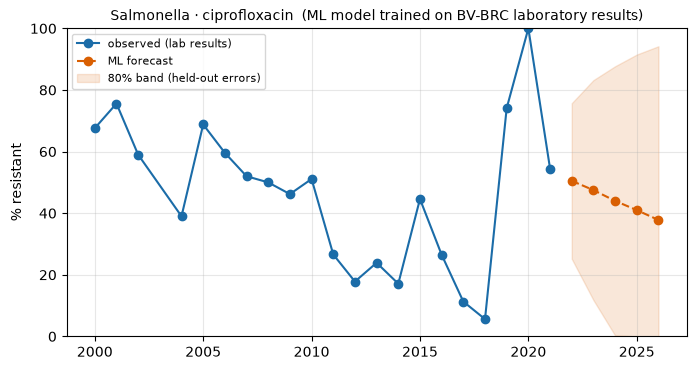

,year,resistant_pct,lo,hi
0,2022,50.5,25.2,75.7
1,2023,47.5,11.8,83.2
2,2024,44.0,0.3,87.7
3,2025,41.0,0.0,91.5
4,2026,37.8,0.0,94.2


In [8]:
sys.path.insert(0, os.path.join(ROOT, 'backend'))
from ml_models.timeline_ml import TimelineMLForecaster
fc = TimelineMLForecaster(os.path.join(ROOT, 'backend', 'trained_models'))
m = fc.forecast('Salmonella', 'ciprofloxacin')
h, f = pd.DataFrame(m['history']), pd.DataFrame(m['forecast'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(h.year, h.resistant_pct, 'o-', color='#1b6ca8', label='observed (lab results)')
ax.plot(f.year, f.resistant_pct, 'o--', color='#d95f02', label='ML forecast')
ax.fill_between(f.year, f.lo, f.hi, color='#d95f02', alpha=0.15, label='80% band (held-out errors)')
ax.set_ylim(0, 100); ax.set_ylabel('% resistant'); ax.set_title(f"{m['organism']} · {m['antibiotic']}  ({m['label']})", fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
f

# B. GAN experiment (A13)

## B1. Method

The base model is A6 (laboratory rows, the forecaster's features, split by genome). A6's split is rebuilt exactly, and **CTGAN is fitted on training rows only**: the rows of antibiotics and genera with fewer than 1,000 training rows. Its synthetic rows are added to A13's training side; **the test set is real and the same as A6's**, so the two models are compared row by row. Synthetic rows that pair a drug with another drug's class, or a species with another genus, are dropped. Fitting CTGAN takes too long on a laptop CPU to repeat here: the code is shown and its saved results are read.

In [9]:
import ctgan_augment as gan
show(gan.generate)

def generate():
    from ctgan import CTGAN
    import torch
    torch.manual_seed(SEED)
    df, tr, te = a6_split()
    train = df.loc[tr]
    rare_ab, rare_ge = rare_sets(train)
    rare = train[train['Antibiotic'].astype(str).isin(rare_ab) | train['genus'].astype(str).isin(rare_ge)]
    real = to_table(rare)
    fit_rows = real.sample(min(len(real), MAX_FIT_ROWS), random_state=SEED)
    print(f'[gan] A6 training rows {int(tr.sum()):,}; rare: {len(rare_ab)} antibiotics, {len(rare_ge)} genera '
          f'(< {RARE_ROWS} training rows each) -> {len(real):,} rows; CTGAN fits on {len(fit_rows):,}, {EPOCHS} epochs')
    t0 = time.time()
    model = CTGAN(epochs=EPOCHS, batch_size=500, verbose=False)
    model.fit(fit_rows, discrete_columns=DISCRETE)
    print(f'[gan] fitted in {time.time() - t0:.0f} s')
    target_n = len(real)
    kept, drawn = [], 0
    while sum(len(k) for k in kept) < target_n and drawn < 20 * target_n:
        batch = model.sample(max(5000, target_n))
        drawn 

In [10]:
import run
show(run.add_synthetic)

def add_synthetic(df, train_mask, test_mask, path, verbose=True):
    """Append synthetic rows (a parquet file, relative to the project root) to the
    training side. Each row gets its own Genome ID (syn_<n>), so grouped folds
    keep treating it as its own genome, and label_source 'synthetic'."""
    full = path if os.path.isabs(path) else os.path.join(os.path.dirname(HERE), path)
    syn = pd.read_parquet(full)
    syn['Genome ID'] = [f'syn_{i}' for i in range(len(syn))]
    syn['label_source'] = 'synthetic'
    for col in df.columns:
        if col not in syn:
            syn[col] = np.nan
    syn = syn[df.columns]
    cats = [c for c in df.columns if str(df[c].dtype) == 'category']
    base = df.copy()
    for c in cats:
        base[c] = base[c].astype(object)
        syn[c] = syn[c].astype(object)
    out = pd.concat([base, syn], ignore_index=True)
    for c in cats:
        out[c] = out[c].astype('category')
    tr = np.concatenate([np.asarray(train_mask), np.ones(len(syn), bo

## B2. Quality of the synthetic rows

In [11]:
q = json.load(open(os.path.join(ROOT, 'experiments', 'gan', 'results', 'ctgan_quality.json')))
print(f"rare antibiotics: {len(q['rare_antibiotics'])}, rare genera: {len(q['rare_genera'])}; real rare training rows "
      f"{q['real_rare_rows']:,}; synthetic rows used {q['synthetic_rows']:,} ({q['synthetic_rows'] / q['sampled']:.0%} of sampled kept)")
print(f"detection AUC {q['detection_auc']} (0.5 = indistinguishable from real); KS distance of the MIC {q['ks_mic_log']}")
pd.Series(q['tvd_per_column'], name='total variation distance (0 = same distribution)').to_frame()

rare antibiotics: 62, rare genera: 21; real rare training rows 21,030; synthetic rows used 21,030 (17% of sampled kept)
detection AUC 0.9999 (0.5 = indistinguishable from real); KS distance of the MIC 0.2916


,total variation distance (0 = same distribution)
Antibiotic,0.4150
drug_class,0.2614
genus,0.3705
species,0.3975
taxon,0.4364
mic_sign,0.3325
has_mic,0.2778
target,0.0302


In [12]:
pd.read_parquet(os.path.join(ROOT, 'experiments', 'cache', 'ctgan_synthetic_A13.parquet')).head(8)

,Antibiotic,drug_class,genus,species,Taxon ID,mic_sign,has_mic,mic_log,mic_value,target,is_lab_confirmed,computational_f1
0,nicotinamide,antitubercular,Mycobacterium,tuberculosis,1773,unknown,0,NaN,NaN,0,1,1.0
1,azithromycin,macrolide,Peptoclostridium,difficile,1496,unknown,0,NaN,NaN,0,1,1.0
2,doripenem,carbapenem,Klebsiella,pneumoniae,573,<=,1,0.151642,0.163744,0,1,1.0
3,cephalothin,beta_lactam,Klebsiella,pneumoniae,573,>,1,3.778791,42.763095,1,1,1.0
4,cefpodoxime,beta_lactam,Shigella,sonnei,624,unknown,0,NaN,NaN,1,1,1.0
5,cycloserine,antitubercular,Mycobacterium,tuberculosis,1773,unknown,0,NaN,NaN,1,1,1.0
6,minocycline,tetracycline,Neisseria,meningitidis,487,==,1,0.047251,0.048386,0,1,1.0
7,clarithromycin,macrolide,Corynebacterium,diphtheriae,1717,unknown,0,NaN,NaN,0,1,1.0


## B3. Effect on the model, on the same real test rows

In [13]:
ev = q['evaluation']
pd.DataFrame([{'test rows': k, 'rows': v['rows'], 'AUC with GAN rows (A13)': v['auc_a13'], 'AUC without (A6)': v['auc_a6'],
               'difference': v['diff'], 'genome bootstrap 95% CI': f"[{v['bootstrap_ci'][0]:+.4f}, {v['bootstrap_ci'][1]:+.4f}]",
               'DeLong p': v['delong_p']} for k, v in ev.items()])

,test rows,rows,AUC with GAN rows (A13),AUC without (A6),difference,genome bootstrap 95% CI,DeLong p
0,all test rows,129992,0.9222,0.9227,-0.0005,"[-0.0007, -0.0002]",5.340793e-06
1,rare antibiotics or genera,5083,0.9323,0.9402,-0.0080,"[-0.0115, -0.0048]",1.378491e-07


The full write-up is `experiments/gan/results/GAN_RESULTS.md`. Whatever the sign of the difference, the experiment answers the question the proposal asked: whether GAN-made data helps the rare classes of this problem.